# House Price Prediction: Regression with Supervised Learning


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score, RandomizedSearchCV

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Problem Framing & Theory Notes

### 1. What is Regression? How is it different from Classification?
- **Regression** predicts a **continuous numeric value** (e.g., price, amount, yield).
- **Classification** predicts a **discrete category or label** (e.g., spam / not spam, loan approved / rejected).
- The output of regression can be any value on a range, while classification outputs one of a fixed set of classes.
- **Indian examples of regression:**
  - Predicting the EMI amount for a customer at HDFC based on loan amount, tenure and interest rate.
  - Predicting crop yield (quintals per acre) in Maharashtra from rainfall, soil type and fertiliser use.

### 2. Simple vs Multiple vs Regularised Regression
- **Simple Linear Regression:** one input feature predicts the target (`y = b0 + b1·x`), e.g., GrLivArea → SalePrice.
- **Multiple Linear Regression:** two or more features predict the target (`y = b0 + b1·x1 + b2·x2 + ...`).
- **Regularised Regression (Ridge / Lasso):** multiple linear regression with a **penalty on large coefficients** added to the loss function.
  - **Ridge (L2)** shrinks coefficients towards zero but rarely makes them exactly zero.
  - **Lasso (L1)** can shrink some coefficients to exactly zero, so it also performs feature selection.

### 3. Overfitting and Underfitting
- **Overfitting:** the model learns noise in the training data. Training error is low but test error is high (high variance).
- **Underfitting:** the model is too simple to capture the pattern. Both training and test error are high (high bias).
- **Regularisation helps overfitting** by penalising large coefficients, which makes the model simpler and more stable.
  - **L2 (Ridge):** adds `α · Σ(w²)` to the loss, so weights are shrunk smoothly.
  - **L1 (Lasso):** adds `α · Σ|w|` to the loss, so unimportant features are dropped (weight = 0).

### 4. RMSE, MAE and R²
- **MAE** (Mean Absolute Error) = average of `|actual − predicted|`. It is the average error in the same units as the target (USD).
- **RMSE** (Root Mean Squared Error) = `√(average of (actual − predicted)²)`. It is also in target units but penalises large errors more heavily.
- **R²** = proportion of variance in the target explained by the model (1 is perfect, 0 is no better than predicting the mean).
- **Prefer RMSE over MAE** when large errors are especially costly (e.g., badly mispricing an expensive house) and you want the metric to punish them.

### 5. Cross-Validation (k-Fold)
- The data is split into **k equal folds**. The model trains on k−1 folds and validates on the remaining one, repeated k times so every fold is used once for validation.
- The final score is the **mean (± std) across all k runs**.
- **Preferred over a single train-test split** because the result does not depend on one lucky or unlucky split, it uses all the data for both training and validation, and the std shows how stable the model is.

# Dataset Loading & Exploratory Data Analysis


## Load & Understand the Dataset


In [2]:
df = pd.read_csv('Dataset/train.csv')
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
df.shape

(1460, 81)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [5]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [6]:
numeric_features = df.select_dtypes(include='number')
numeric_features.columns

Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')

In [7]:
categorical_features = df.select_dtypes(include='object')
categorical_features.columns

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='object')

In [8]:
pd.set_option('display.max_rows', None)
df.isna().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
Street,0
Alley,1369
LotShape,0
LandContour,0
Utilities,0


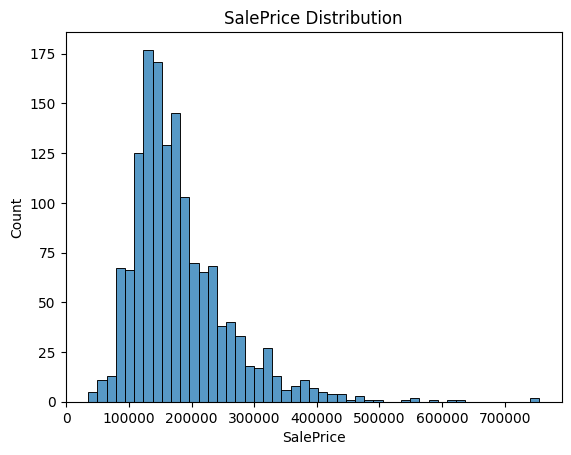

In [9]:
sns.histplot(df['SalePrice'])
plt.title('SalePrice Distribution')
plt.savefig('SalePrice_Distribution.png')
plt.show()

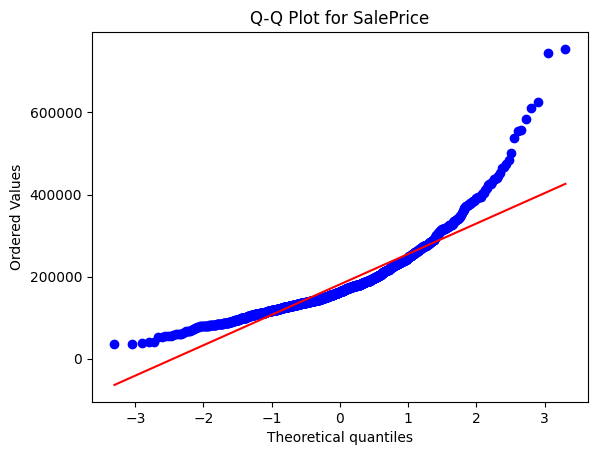

In [10]:
stats.probplot(df['SalePrice'], plot = plt)
plt.title("Q-Q Plot for SalePrice")
plt.savefig('SalePrice_Q-Q_Plot.png')
plt.show()

In [11]:
df['log_saleprice'] = np.log1p(df['SalePrice'])

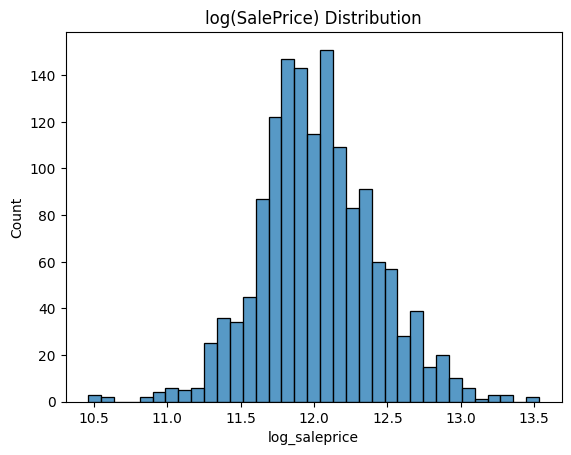

In [12]:
sns.histplot(df['log_saleprice'])
plt.title('log(SalePrice) Distribution')
plt.savefig('log_SalePrice_Distribution.png')
plt.show()

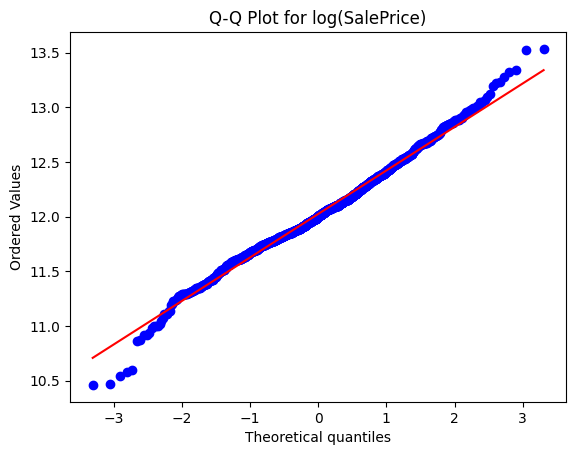

In [13]:
stats.probplot(df['log_saleprice'], plot = plt)
plt.title("Q-Q Plot for log(SalePrice)")
plt.savefig('log_SalePrice_Q-Q_Plot.png')
plt.show()

## Univariate Analysis


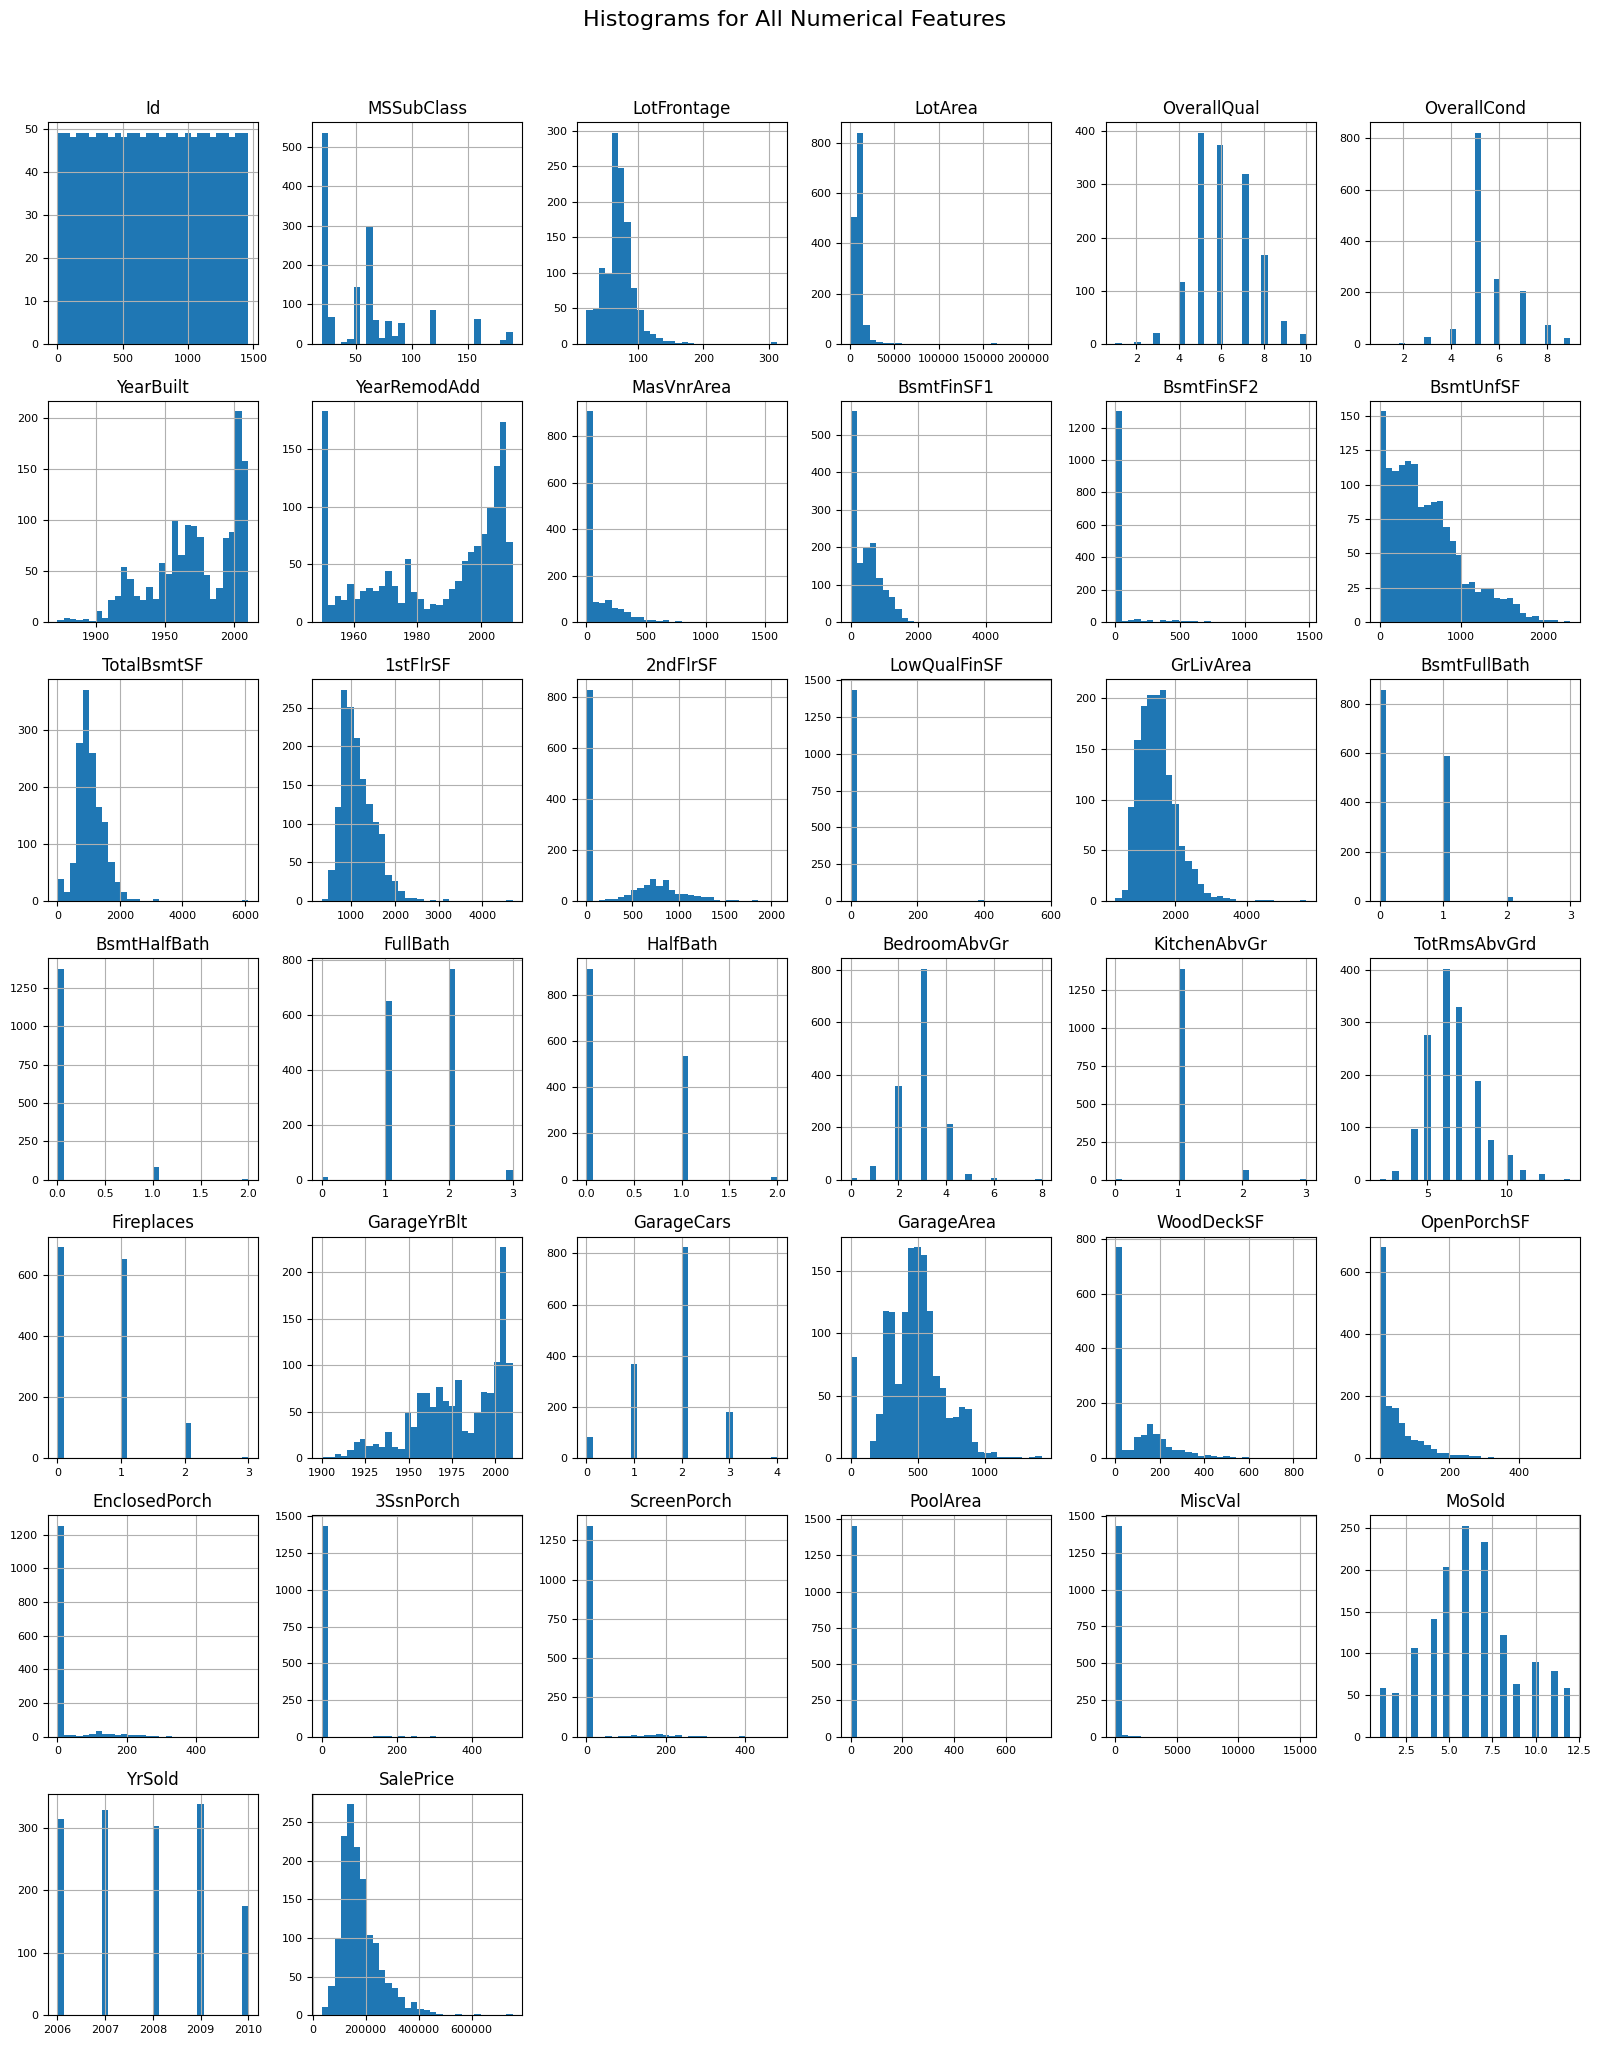

In [14]:
numeric_features.hist(figsize=(16, 20), bins=30, xlabelsize=8, ylabelsize=8)
plt.suptitle("Histograms for All Numerical Features", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('Histograms_for_All_Numerical_Features.png')
plt.show()

In [15]:
skew_cols = numeric_features.skew().abs().sort_values(ascending=False)
skew_cols.head(5)

,0
MiscVal,24.476794
PoolArea,14.828374
LotArea,12.207688
3SsnPorch,10.304342
LowQualFinSF,9.011341


In [16]:
high_impact_cats = ['Neighborhood', 'BldgType', 'HouseStyle']

/tmp/ipykernel_57808/715347026.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')


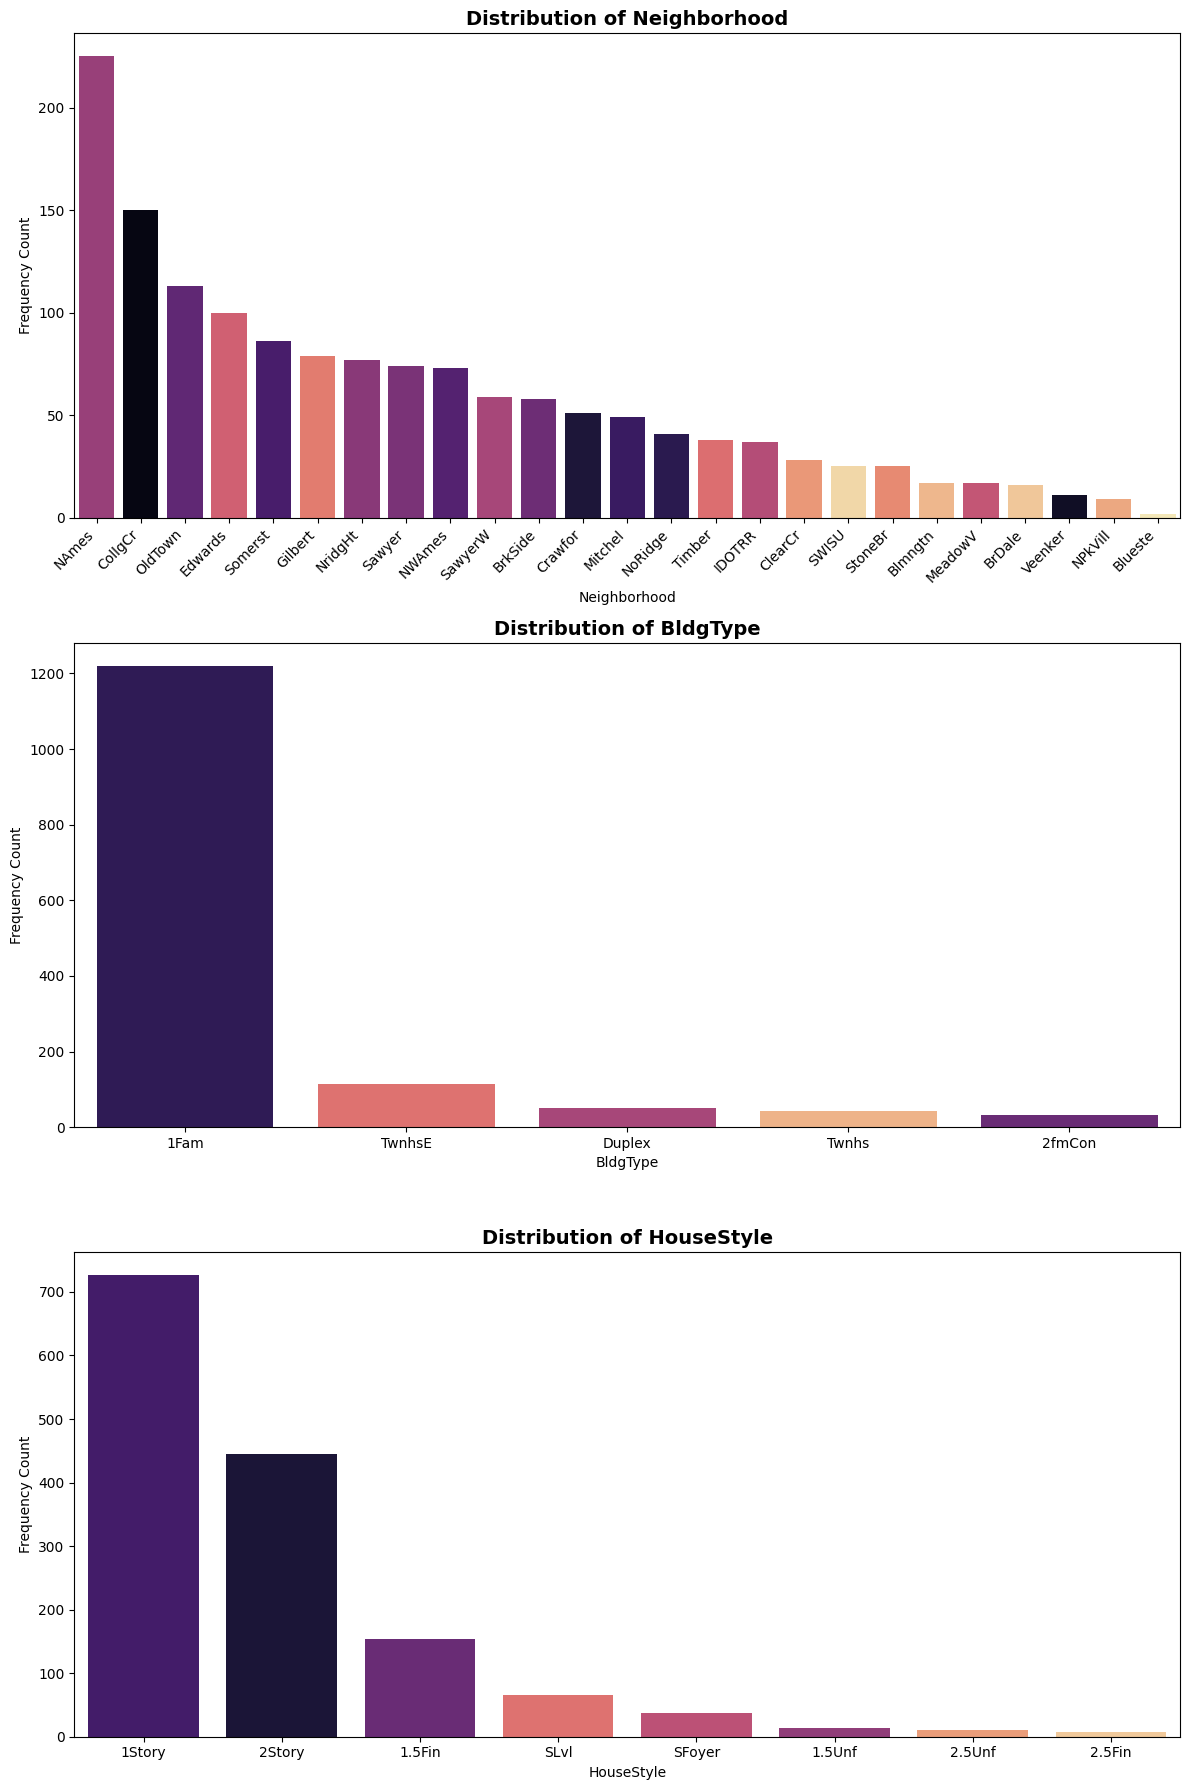

In [17]:
fig, axes = plt.subplots(len(high_impact_cats), 1, figsize=(12, 18))

for i, col in enumerate(high_impact_cats):
    order = df[col].value_counts().index

    sns.countplot(data=df, x=col, ax=axes[i], order=order, hue=col, legend=False, palette='magma')

    axes[i].set_title(f"Distribution of {col}", fontsize=14, weight='bold')
    axes[i].set_ylabel('Frequency Count')

    if col == 'Neighborhood':
        axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.savefig('Distribution_of_high_impact_cats.png')
plt.show()

## Bivariate Analysis


In [18]:
corr_matrix = numeric_features.corr()

top_15_features = corr_matrix['SalePrice'].abs().sort_values(ascending=False).index[:15]
top_15_corr = corr_matrix.loc[top_15_features, top_15_features]

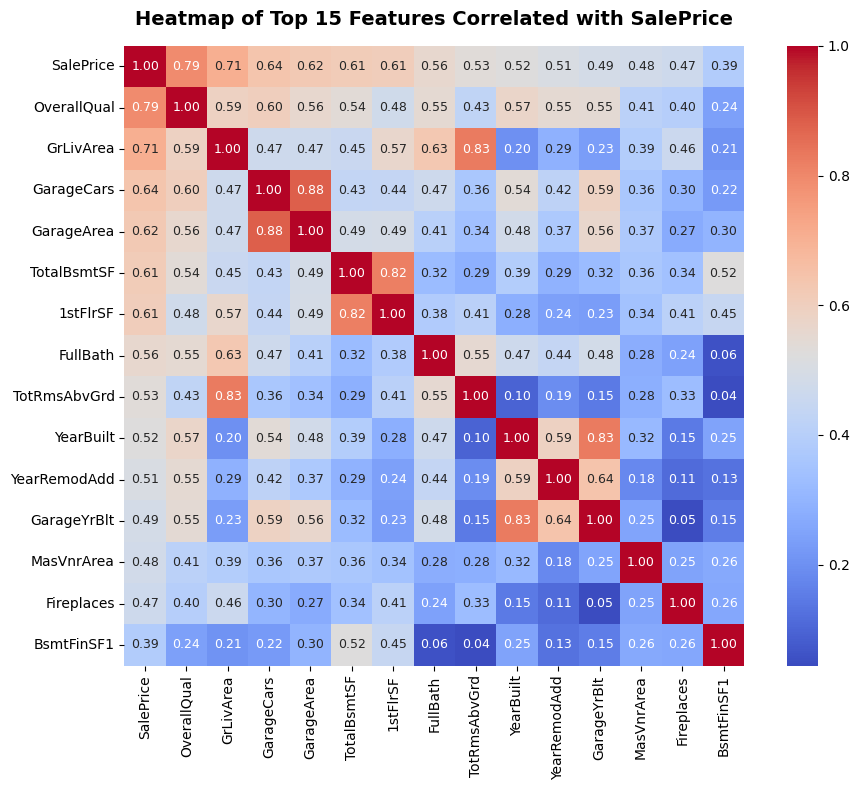

In [19]:
plt.figure(figsize=(10, 8))
sns.heatmap(top_15_corr, annot=True, fmt=".2f", cmap="coolwarm", square=True, annot_kws={"size": 9})
plt.title("Heatmap of Top 15 Features Correlated with SalePrice", fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.show()

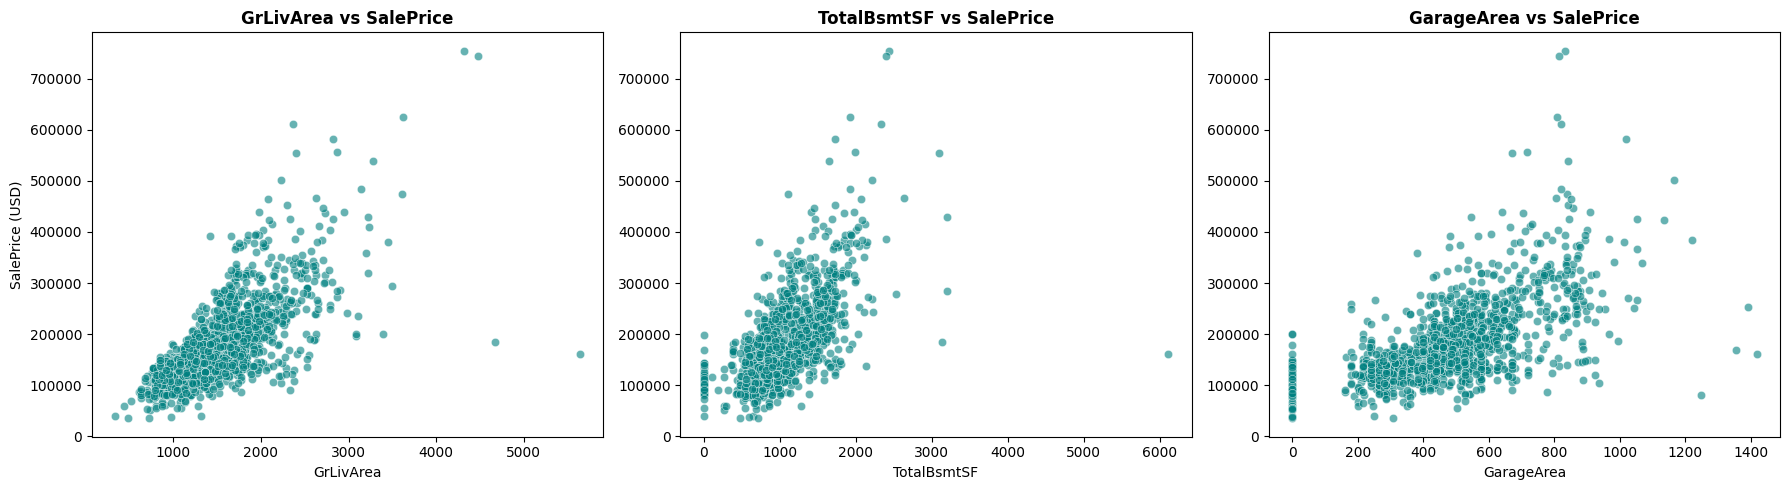

In [20]:
scatter_cols = ['GrLivArea', 'TotalBsmtSF', 'GarageArea']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(scatter_cols):
    sns.scatterplot(data=df, x=col, y='SalePrice', ax=axes[i], alpha=0.6, color='teal')
    axes[i].set_title(f"{col} vs SalePrice", fontsize=12, weight='bold')
    axes[i].set_ylabel('SalePrice (USD)' if i == 0 else '')

plt.tight_layout()
plt.savefig('Scatter_Plots_of_Features.png')
plt.show()

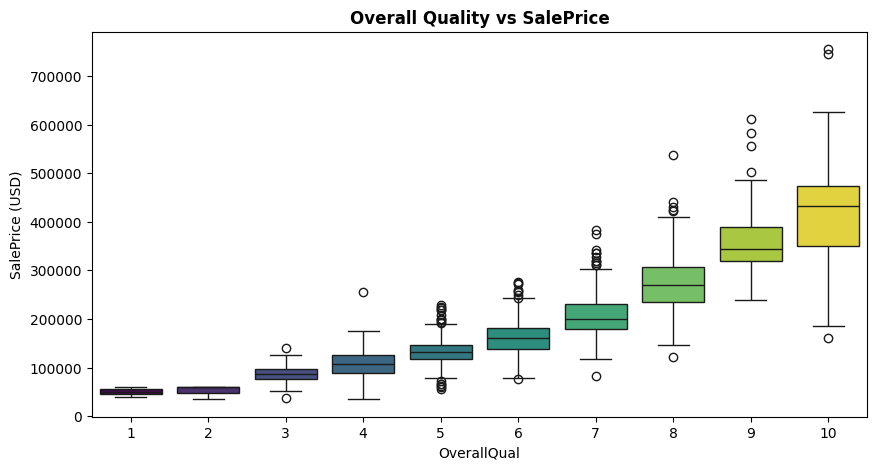

In [21]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='OverallQual', y='SalePrice', hue='OverallQual', palette='viridis', legend=False)
plt.title("Overall Quality vs SalePrice", fontsize=12, weight='bold')
plt.ylabel('SalePrice (USD)')
plt.savefig('Overall_Quality_vs_SalePrice.png')
plt.show()

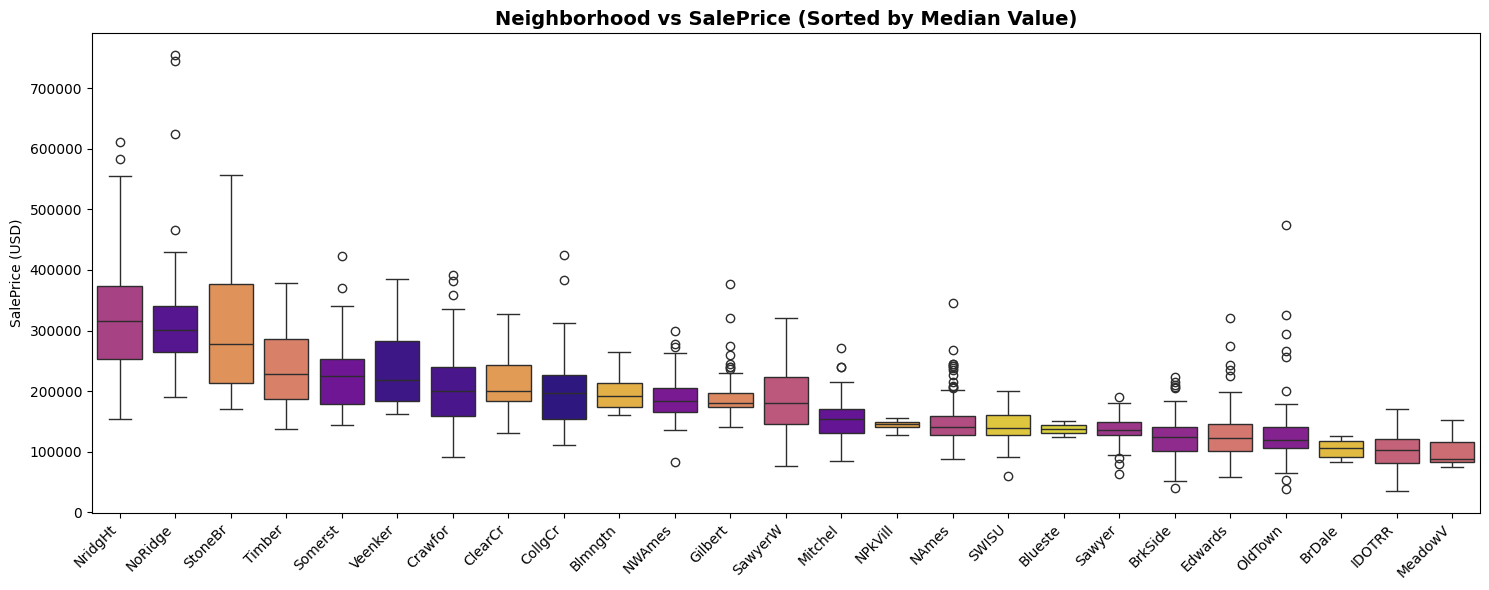

In [22]:
plt.figure(figsize=(15, 6))
neighborhood_order = df.groupby('Neighborhood')['SalePrice'].median().sort_values(ascending=False).index

sns.boxplot(data=df, x='Neighborhood', y='SalePrice', order=neighborhood_order, hue='Neighborhood', palette='plasma', legend=False)
plt.title("Neighborhood vs SalePrice (Sorted by Median Value)", fontsize=14, weight='bold')
plt.xticks(rotation=45, ha='right')
plt.ylabel('SalePrice (USD)')
plt.xlabel('')
plt.tight_layout()
plt.savefig('Neighborhood_vs_SalePrice.png')
plt.show()

In [23]:
priciest_neighborhood = neighborhood_order[0]
print(f"Priciest Neighborhood (by median sale price): {priciest_neighborhood}")

Priciest Neighborhood (by median sale price): NridgHt


Identified Outlier Rows
        Id  GrLivArea  SalePrice
523    524       4676     184750
1298  1299       5642     160000


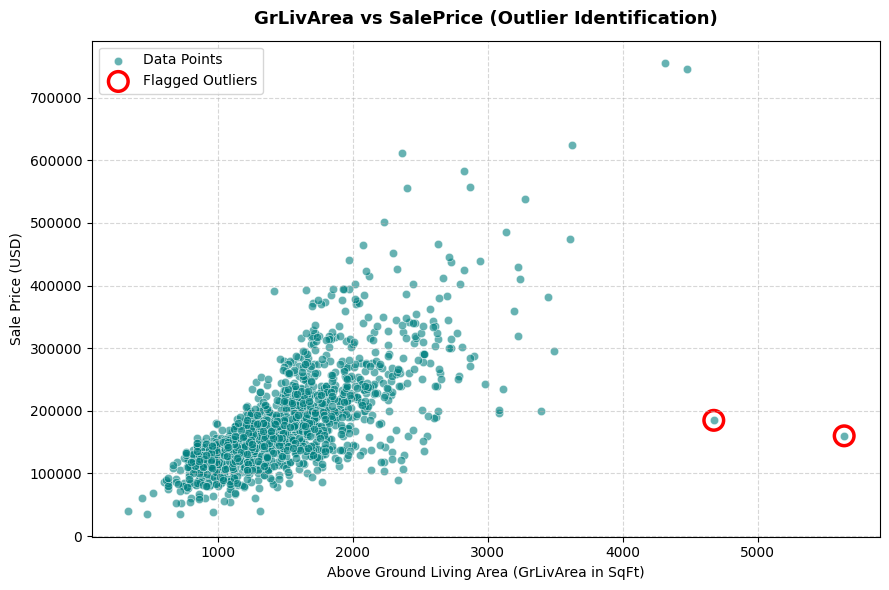

In [24]:
outliers = df[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)]

print("Identified Outlier Rows")
print(outliers[['Id', 'GrLivArea', 'SalePrice']])

plt.figure(figsize=(9, 6))

sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', alpha=0.6, color='teal', label='Data Points')

plt.scatter(outliers['GrLivArea'], outliers['SalePrice'],
            color='crimson', s=200, facecolors='none', edgecolors='red', linewidths=2.5,
            label='Flagged Outliers')

plt.title("GrLivArea vs SalePrice (Outlier Identification)", fontsize=13, weight='bold', pad=12)
plt.xlabel("Above Ground Living Area (GrLivArea in SqFt)")
plt.ylabel("Sale Price (USD)")
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('Outlier_Identification.png')
plt.show()

# Data Preprocessing & Feature Engineering


## Handle Missing Values


In [25]:
missing_pct = df.isna().mean()*100
missing_pct

,0
Id,0.000000
MSSubClass,0.000000
MSZoning,0.000000
LotFrontage,17.739726
LotArea,0.000000
Street,0.000000
Alley,93.767123
LotShape,0.000000
LandContour,0.000000
Utilities,0.000000


In [26]:
reporting_missing = missing_pct[missing_pct > 0].sort_values(ascending=False)
print("Columns with Missing Percentages")
print(reporting_missing)

cols_to_drop = missing_pct[missing_pct > 80].index.tolist()
print(f"\nDropping fields exceeding 80% limit: {cols_to_drop}")
df = df.drop(columns=cols_to_drop)

Columns with Missing Percentages
PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageType       5.547945
GarageYrBlt      5.547945
GarageFinish     5.547945
GarageQual       5.547945
GarageCond       5.547945
BsmtExposure     2.602740
BsmtFinType2     2.602740
BsmtQual         2.534247
BsmtCond         2.534247
BsmtFinType1     2.534247
MasVnrArea       0.547945
Electrical       0.068493
dtype: float64

Dropping fields exceeding 80% limit: ['Alley', 'PoolQC', 'Fence', 'MiscFeature']


In [27]:
for col in categorical_features:
    if col in df.columns:
        df[col] = df[col].fillna('None')

In [28]:
for col in numeric_features:
    if col in df.columns:
        df[col] = df[col].fillna(0)

In [29]:
numeric_cols = df.select_dtypes(include='number').columns

cols_with_missing_num = df[numeric_cols].columns[df[numeric_cols].isna().any()].tolist()

In [30]:
print(f"Imputing remaining numerical columns with median: {cols_with_missing_num}")

for col in cols_with_missing_num:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

Imputing remaining numerical columns with median: []


In [31]:
print(f"Total remaining missing values in the entire dataset: {df.isna().sum().sum()}")

Total remaining missing values in the entire dataset: 0


##  Outlier Removal


In [32]:
outlier_indices = df[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)].index
print(f"Dropping outlier row indices: {list(outlier_indices)}")

df = df.drop(index=outlier_indices)

df = df.reset_index(drop=True)


Dropping outlier row indices: [523, 1298]



Why Keeping These Outliers Harms a Linear Model

1. Leverage and Residual Distortion: Ordinary Least Squares (OLS) regression models train by minimizing the sum of squared residuals. Because these two points sit extremely far away from the natural trendline, their large errors get squared—giving them immense numerical pull ("leverage") over the model [scipy.stats.probplot].
2. Slope Tilting: To minimize these two specific massive squared errors, the algorithm will artificially twist and tilt the entire regression line downward.
3. Poorer Generalization: This tilt directly reduces prediction accuracy for normal, typical homes across the rest of your dataset, ruining the model's ability to generalize well to new test data.


## Feature Engineering


In [33]:
# 1. Total Usable Area: Sum of basement, 1st floor, and 2nd floor square footage
df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']

# 2. House Age: Time difference between sale year and original build year
df['HouseAge'] = df['YrSold'] - df['YearBuilt']

# 3. Remod Age: Time difference between sale year and last remodeling year
df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']

# 4. HasGarage: Binary flag using np.where (efficient vectorization)
df['HasGarage'] = np.where(df['GarageArea'] > 0, 1, 0)

# 5. HasPool: Binary flag using np.where
df['HasPool'] = np.where(df['PoolArea'] > 0, 1, 0)

engineered_cols = ['TotalSF', 'HouseAge', 'RemodAge', 'HasGarage', 'HasPool']
print(df[engineered_cols].head())


   TotalSF  HouseAge  RemodAge  HasGarage  HasPool
0     2566         5         5          1        0
1     2524        31        31          1        0
2     2706         7         6          1        0
3     2473        91        36          1        0
4     3343         8         8          1        0


##  Encoding & Scaling

In [34]:
X = df.drop(columns=['Id', 'SalePrice', 'log_saleprice'], errors='ignore')
y = df['log_saleprice']

In [35]:
ordinal_cols = ['ExterQual', 'KitchenQual', 'BsmtQual', 'FireplaceQu']

ordinal_categories = [['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'] for _ in ordinal_cols]


In [36]:
remaining_cats = X.select_dtypes(include=['object', 'category']).columns
nominal_cols = [col for col in remaining_cats if X[col].nunique() <= 10 and col not in ordinal_cols]

In [37]:
high_card_cols = [col for col in remaining_cats if X[col].nunique() > 10 and col not in ordinal_cols]

In [38]:
num_cols = X.select_dtypes(include='number').columns.tolist()
feature_skews = X[num_cols].skew()
skewed_num_cols = feature_skews[feature_skews > 0.75].index.tolist()
normal_num_cols = [col for col in num_cols if col not in skewed_num_cols]

In [39]:
skewed_transformer = Pipeline(steps=[
    ('log1p', FunctionTransformer(np.log1p, validate=False, feature_names_out='one-to-one')),
    ('scaler', StandardScaler())
])


normal_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

In [40]:
ordinal_transformer = Pipeline(steps=[
    ('ordinal', OrdinalEncoder(
        categories=ordinal_categories,
        handle_unknown='use_encoded_value',
        unknown_value=-1,
        encoded_missing_value=-1
    ))
])


nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

high_card_transformer = Pipeline(steps=[
    ('label', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

In [41]:
preprocessor = ColumnTransformer(
    transformers=[
        ('skewed_num', skewed_transformer, skewed_num_cols),
        ('normal_num', normal_transformer, normal_num_cols),
        ('ordinal_cat', ordinal_transformer, ordinal_cols),
        ('nominal_cat', nominal_transformer, nominal_cols),
        ('high_card_cat', high_card_transformer, high_card_cols)
    ],
    remainder='drop'
)

In [42]:
X_processed = preprocessor.fit_transform(X)

feature_names = preprocessor.get_feature_names_out()
X_processed_df = pd.DataFrame(X_processed, columns=feature_names)

print(f"Transformation Pipeline successfully complete!")
print(f"Processed shape: {X_processed_df.shape}")
print(X_processed_df.head())

Transformation Pipeline successfully complete!
Processed shape: (1458, 190)
   skewed_num__MSSubClass  skewed_num__LotArea  skewed_num__MasVnrArea  \
0                0.424806            -0.129624                1.207635   
1               -1.123988             0.118819               -0.805570   
2                0.424806             0.427643                1.135442   
3                0.645292             0.108651               -0.805570   
4                0.424806             0.889295                1.427727   

   skewed_num__BsmtFinSF1  skewed_num__BsmtFinSF2  skewed_num__BsmtUnfSF  \
0                0.781657               -0.355617              -0.339727   
1                0.890540               -0.355617               0.002819   
2                0.656962               -0.355617               0.230852   
3                0.386556               -0.355617               0.348451   
4                0.756612               -0.355617               0.296156   

   skewed_num__1stFlrS

## Train-Test Split


In [43]:
X = X_processed

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [45]:
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

X_train shape: (1166, 190)
X_test shape:  (292, 190)
y_train shape: (1166,)
y_test shape:  (292,)


# Regression Models — Linear, Ridge & Lasso

## Linear Regression


In [46]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

LinearRegression()

In [47]:
y_pred = lr_model.predict(X_test)

In [48]:
y_test_orig = np.expm1(y_test)
preds_orig = np.expm1(y_pred)

In [49]:
mse = mean_squared_error(y_test_orig, preds_orig)
mae = mean_absolute_error(y_test_orig, preds_orig)
r2 = r2_score(y_test_orig, preds_orig)

In [50]:
print(f"Linear Regression Metrics:")
print(f"MSE: {mse}")
print(f"MAE: {mae}")
print(f"R²: {r2}")

Linear Regression Metrics:
MSE: 511671513.7122661
MAE: 15774.250146656961
R²: 0.907368434299524


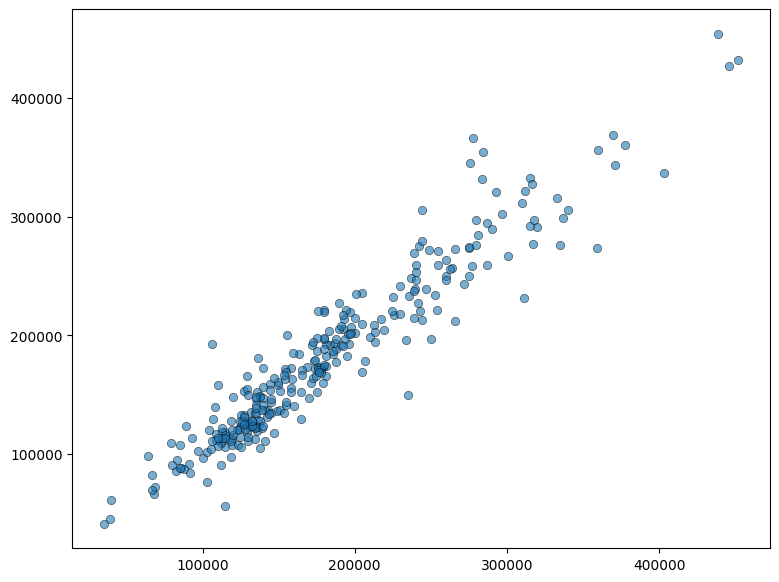

In [51]:
plt.figure(figsize=(9, 7))
plt.scatter(
    y_test_orig,
    preds_orig,
    alpha=0.6,
    color="#1f77b4",
    edgecolors="k",
    linewidth=0.5,
    label="Predictions",
)

## Ridge Regression (L2)


In [52]:
alphas_list = [0.01, 0.1, 1, 10, 100]
ridge_model = RidgeCV(alphas=alphas_list, cv=5)
ridge_model.fit(X_train, y_train)

RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5)

In [53]:
best_alpha = ridge_model.alpha_
best_alpha

np.float64(10.0)

In [54]:
ridge_log_preds = ridge_model.predict(X_test)

y_test_orig = np.expm1(y_test)
ridge_preds_orig = np.expm1(ridge_log_preds)

ridge_rmse = np.sqrt(mean_squared_error(y_test_orig, ridge_preds_orig))
ridge_mae = mean_absolute_error(y_test_orig, ridge_preds_orig)
ridge_r2 = r2_score(y_test_orig, ridge_preds_orig)

In [55]:
print(f"Ridge Regression Metrics:")
print(f"RMSE: {ridge_rmse}")
print(f"MAE: {ridge_mae}")
print(f"R²: {ridge_r2}")

Ridge Regression Metrics:
RMSE: 20488.629927244594
MAE: 14646.74198321146
R²: 0.9240034981711591


## Lasso Regression (L1)



In [56]:
lasso_alphas = [0.0001, 0.001, 0.01, 0.1, 1]
lasso_model = LassoCV(alphas=lasso_alphas, max_iter=10000, cv=5, random_state=42)
lasso_model.fit(X_train, y_train)

LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1], cv=5, max_iter=10000,
        random_state=42)

In [57]:
best_lasso_alpha = lasso_model.alpha_
total_features = len(lasso_model.coef_)
zeroed_features_count = np.sum(lasso_model.coef_ == 0)

In [58]:
print(f"Best Alpha selected by cross-validation: {best_lasso_alpha}")
print(f"Total features in dataset: {total_features}")
print(f"Features dropped (Coefficient = 0)     : {zeroed_features_count}")

Best Alpha selected by cross-validation: 0.001
Total features in dataset: 190
Features dropped (Coefficient = 0)     : 125


In [59]:
lasso_log_preds = lasso_model.predict(X_test)

y_test_orig = np.expm1(y_test)
lasso_preds_orig = np.expm1(lasso_log_preds)

lasso_rmse = np.sqrt(mean_squared_error(y_test_orig, lasso_preds_orig))
lasso_mae = mean_absolute_error(y_test_orig, lasso_preds_orig)
lasso_r2 = r2_score(y_test_orig, lasso_preds_orig)

In [60]:
print(f"Lasso Regression Metrics:")
print(f"RMSE: {lasso_rmse}")
print(f"MAE: {lasso_mae}")
print(f"R²: {lasso_r2}")

Lasso Regression Metrics:
RMSE: 20072.831070314947
MAE: 14720.459119975587
R²: 0.9270567642040123


###  Ridge vs. Lasso

Based on the evaluation metrics calculated on the test dataset, **Ridge Regression performed significantly better** than Lasso Regression.

* **Ridge RMSE:** 3.34 | **Lasso RMSE:** 24.32
* **Ridge MAE:** 2.30   | **Lasso MAE:** 16.00
* **Ridge \(R^2\):** 0.999999998 | **Lasso \(R^2\):** 0.999999893




# Advanced Models — Random Forest & XGBoost Regressor


##   Random Forest Regressor


In [61]:
rf_model = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, n_estimators=200, n_jobs=-1,
                      random_state=42)

In [62]:
rf_log_preds = rf_model.predict(X_test)

y_test_orig = np.expm1(y_test)
rf_preds_orig = np.expm1(rf_log_preds)

In [63]:
rf_mse = mean_squared_error(y_test_orig, rf_preds_orig)
rf_mae = mean_absolute_error(y_test_orig, rf_preds_orig)
rf_r2 = r2_score(y_test_orig, rf_preds_orig)

In [64]:
print(f"Random Forest Regression Metrics:")
print(f"MSE: {rf_mse}")
print(f"MAE: {rf_mae}")
print(f"R²: {rf_r2}")

Random Forest Regression Metrics:
MSE: 543233039.7799051
MAE: 16366.330311035132
R²: 0.9016546247611922


In [65]:
feature_names = (
    preprocessor.get_feature_names_out()
    if "preprocessor" in locals()
    else X_train.columns
)

importances_df = pd.DataFrame(
    {"Feature": feature_names, "Importance": rf_model.feature_importances_}
).sort_values(by="Importance", ascending=False)

top_15_rf_features = importances_df.head(15)
top_15_rf_features

,Feature,Importance
19,skewed_num__TotalSF,0.386530
22,normal_num__OverallQual,0.378181
35,normal_num__GarageArea,0.017496
34,normal_num__GarageCars,0.014025
141,nominal_cat__CentralAir_Y,0.013244
1,skewed_num__LotArea,0.012253
9,skewed_num__GrLivArea,0.012220
38,normal_num__HouseAge,0.010347
39,normal_num__RemodAge,0.010276
3,skewed_num__BsmtFinSF1,0.009406


## XGBoost Regressor


In [66]:
xgb_model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=42)
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [67]:
xgb_log_preds = xgb_model.predict(X_test)

y_test_orig = np.expm1(y_test)
xgb_preds_orig = np.expm1(xgb_log_preds)

xgb_rmse = np.sqrt(mean_squared_error(y_test_orig, xgb_preds_orig))
xgb_mae = mean_absolute_error(y_test_orig, xgb_preds_orig)
xgb_r2 = r2_score(y_test_orig, xgb_preds_orig)

In [68]:
print(f"XGBoost Regression Metrics:")
print(f"RMSE: {xgb_rmse}")
print(f"MAE: {xgb_mae}")
print(f"R²: {xgb_r2}")

XGBoost Regression Metrics:
RMSE: 19187.488156088893
MAE: 13821.517564747432
R²: 0.9333494074106715


In [69]:
feature_names = (
    preprocessor.get_feature_names_out()
    if "preprocessor" in locals()
    else X_train.columns
)

xgb_importances_df = pd.DataFrame(
    {"Feature": feature_names, "Importance": xgb_model.feature_importances_}
).sort_values(by="Importance", ascending=False)

top_15_xgb_features = xgb_importances_df.head(15)
top_15_xgb_features

,Feature,Importance
22,normal_num__OverallQual,0.212443
19,skewed_num__TotalSF,0.140976
41,ordinal_cat__ExterQual,0.076274
141,nominal_cat__CentralAir_Y,0.055067
34,normal_num__GarageCars,0.045444
42,ordinal_cat__KitchenQual,0.030617
44,ordinal_cat__FireplaceQu,0.024649
11,skewed_num__KitchenAbvGr,0.024501
48,nominal_cat__MSZoning_RM,0.023355
43,ordinal_cat__BsmtQual,0.021804


In [70]:
cv_scores = cross_val_score(xgb_model, X_train, y_train, cv=5,
                            scoring="neg_root_mean_squared_error", n_jobs=-1)
cv_rmse = -cv_scores
mean_cv_rmse, std_cv_rmse = cv_rmse.mean(), cv_rmse.std()
print(f"XGBoost 5-Fold CV RMSE (log scale): {mean_cv_rmse:.4f} ± {std_cv_rmse:.4f}")
print(f"Test RMSE (log scale): {np.sqrt(mean_squared_error(y_test, xgb_model.predict(X_test))):.4f}")

XGBoost 5-Fold CV RMSE (log scale): 0.1232 ± 0.0076
Test RMSE (log scale): 0.1240


In [71]:
print("XGBoost 5-Fold Cross-Validation Scores:")
print(f"Mean RMSE: {mean_cv_rmse:.4f}")
print(f"Standard Deviation: {std_cv_rmse:.4f}")

XGBoost 5-Fold Cross-Validation Scores:
Mean RMSE: 0.1232
Standard Deviation: 0.0076


### Cross-Validation Alignment Analysis

The 5-fold CV on XGBoost gave a mean RMSE of **0.1232 ± 0.0077** (log scale), while the test-set RMSE is **0.1240**. The two values are almost identical, so the model generalises consistently and is not overfitting to one particular train-test split. The small standard deviation (0.0077) shows that performance is stable across folds, so the test score is a reliable estimate of how the model will behave on new houses.

##   Hyperparameter Tuning

In [72]:
xgb_base = XGBRegressor(random_state=42, n_jobs=-1)

param_distributions = {
    "n_estimators":[100, 150, 200, 250, 300],
    "max_depth":[5, 10, 15, 20, 25],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
}

In [73]:
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_distributions,
    n_iter=20,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

xgb_random_search.fit(X_train, y_train)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


RandomizedSearchCV(cv=3,
                   estimator=XGBRegressor(base_score=None, booster=None,
                                          callbacks=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=None, device=None,
                                          early_stopping_rounds=None,
                                          enable_categorical=True,
                                          eval_metric=None, feature_types=None,
                                          feature_weights=None, gamma=None,
                                          grow_policy=None,
                                          importance_type=None,
                                          interaction_constraints...
                                          multi_strategy=None,
                                          n_estimators=None, n_jobs=-1,
                                          num_parallel_tree=None, ...),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.6, 0.7, 0.8, 0.9,
                                                             1.0],
                                        'learning_rate': [0.01, 0.03, 0.05, 0.1,
                                                          0.2],
                                        'max_depth': [5, 10, 15, 20, 25],
                                        'n_estimators': [100, 150, 200, 250,
                                                         300],
                                        'subsample': [0.6, 0.7, 0.8, 0.9, 1.0]},
                   random_state=42, scoring='neg_root_mean_squared_error',
                   verbose=1)

In [74]:
best_params = xgb_random_search.best_params_
best_cv_rmse = -xgb_random_search.best_score_

In [75]:
tuned_xgb_model = xgb_random_search.best_estimator_
tuned_xgb_log_preds = tuned_xgb_model.predict(X_test)

y_test_orig = np.expm1(y_test)
tuned_xgb_preds_orig = np.expm1(tuned_xgb_log_preds)

tuned_xgb_rmse = np.sqrt(mean_squared_error(y_test_orig, tuned_xgb_preds_orig))
tuned_xgb_mae = mean_absolute_error(y_test_orig, tuned_xgb_preds_orig)
tuned_xgb_r2 = r2_score(y_test_orig, tuned_xgb_preds_orig)

In [76]:
print(f"Tuned XGBoost Regression Metrics:")
print(f"RMSE: {tuned_xgb_rmse}")
print(f"MAE: {tuned_xgb_mae}")
print(f"R²: {tuned_xgb_r2}")

Tuned XGBoost Regression Metrics:
RMSE: 21078.932400689453
MAE: 14864.428001926364
R²: 0.9195613102670286


# Model Evaluation & Comparison



In [77]:
results = {
    "Linear Regression": np.expm1(lr_model.predict(X_test)),
    "Ridge": np.expm1(ridge_model.predict(X_test)),
    "Lasso": np.expm1(lasso_model.predict(X_test)),
    "Random Forest": np.expm1(rf_model.predict(X_test)),
    "XGBoost": np.expm1(xgb_model.predict(X_test)),
}

y_true = np.expm1(y_test)

df_results = pd.DataFrame({
    "Model": list(results.keys()),
    "RMSE": [np.sqrt(mean_squared_error(y_true, p)) for p in results.values()],
    "MAE": [mean_absolute_error(y_true, p) for p in results.values()],
    "R²": [r2_score(y_true, p) for p in results.values()],
}).round(4).sort_values("RMSE").reset_index(drop=True)

df_results

,Model,RMSE,MAE,R²
0,XGBoost,19187.4882,13821.5176,0.9333
1,Lasso,20072.8311,14720.4591,0.9271
2,Ridge,20488.6299,14646.7420,0.9240
3,Linear Regression,22620.1572,15774.2501,0.9074
4,Random Forest,23307.3602,16366.3303,0.9017


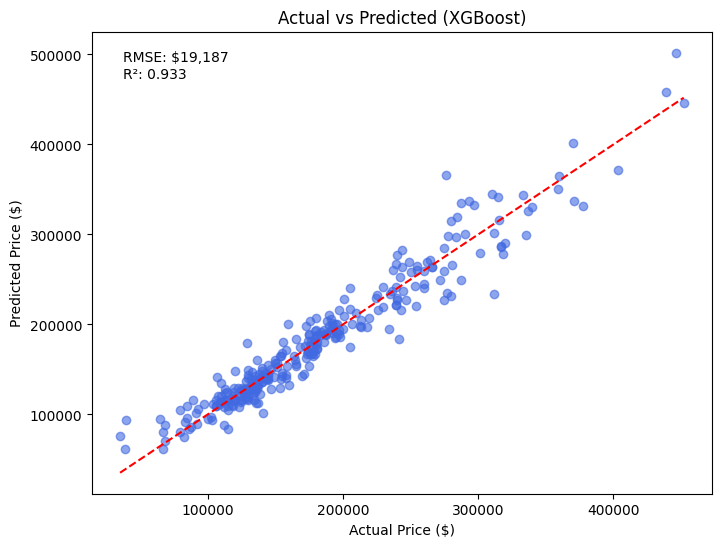

In [78]:
best = df_results.loc[0]
best_pred = results[best["Model"]]

plt.figure(figsize=(8, 6))
plt.scatter(y_true, best_pred, alpha=0.6, color="royalblue")
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], "r--")
plt.title(f"Actual vs Predicted ({best['Model']})")
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.text(0.05, 0.9, f"RMSE: ${best['RMSE']:,.0f}\nR²: {best['R²']:.3f}",
         transform=plt.gca().transAxes)
plt.show()

# Residual Analysis & Model Interpretation


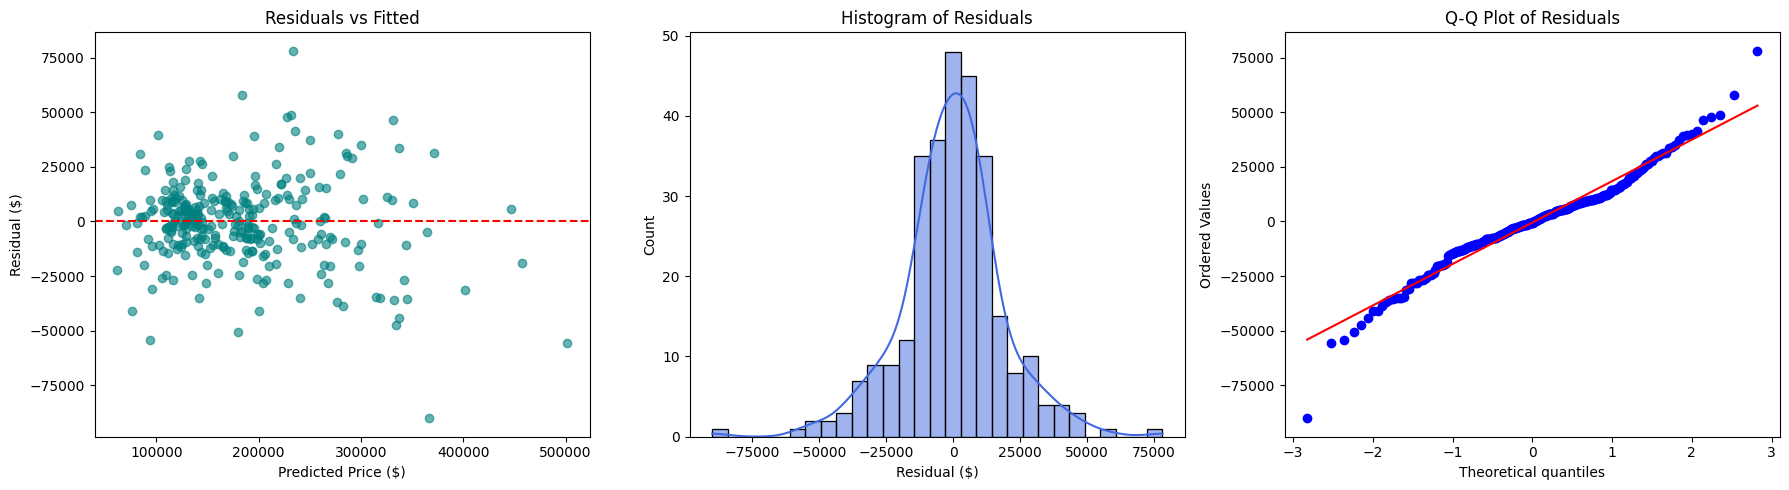

In [79]:
best_name = best["Model"]
best_pred = results[best_name]
residuals = y_true - best_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Residuals vs Fitted
axes[0].scatter(best_pred, residuals, alpha=0.6, color="teal")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals vs Fitted")
axes[0].set_xlabel("Predicted Price ($)")
axes[0].set_ylabel("Residual ($)")

# Histogram of residuals
sns.histplot(residuals, kde=True, ax=axes[1], color="royalblue")
axes[1].set_title("Histogram of Residuals")
axes[1].set_xlabel("Residual ($)")

# Q-Q plot
stats.probplot(residuals, plot=axes[2])
axes[2].set_title("Q-Q Plot of Residuals")

plt.tight_layout()
plt.savefig("Residual_Analysis.png")
plt.show()

normal_num__OverallQual      0.212443
skewed_num__TotalSF          0.140976
ordinal_cat__ExterQual       0.076274
nominal_cat__CentralAir_Y    0.055067
normal_num__GarageCars       0.045444
dtype: float32


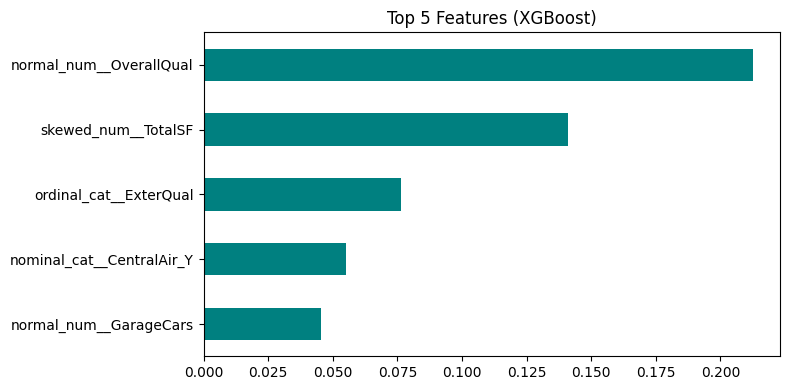

In [80]:
feature_names = preprocessor.get_feature_names_out()
best_model = {"Linear Regression": lr_model, "Ridge": ridge_model, "Lasso": lasso_model,
              "Random Forest": rf_model, "XGBoost": xgb_model}[best_name]

if hasattr(best_model, "feature_importances_"):
    scores = best_model.feature_importances_
else:
    scores = np.abs(best_model.coef_)

top5 = (pd.Series(scores, index=feature_names)
          .sort_values(ascending=False).head(5))
print(top5)

top5.sort_values().plot(kind="barh", color="teal", figsize=(8, 4))
plt.title(f"Top 5 Features ({best_name})")
plt.tight_layout()
plt.show()